# 01 - Kalman filter for a drifting hedge ratio (synthetic data)

A fixed OLS hedge ratio assumes the relationship between two assets never changes. In practice it drifts. Here I treat the hedge ratio $\beta_t$ as a hidden state that follows a random walk, and use a Kalman filter to update it every day.

Before touching real prices I simulate data where I know the true $\beta_t$, so I can check that the filter actually tracks it.

**Model**

$$y_t = \beta_t x_t + \epsilon_t, \quad \epsilon_t \sim N(0, R)$$
$$\beta_t = \beta_{t-1} + w_t, \quad w_t \sim N(0, Q)$$

**Intuition:** each day I ask how sure I am about my current $\beta$, and how noisy today's observation is. If I'm unsure and the data is clean, I trust the data. If I'm sure and the data is noisy, I mostly ignore it. The Kalman gain is that trust weight.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
num_days = 500
true_beta_start = 1.5
true_process_std = 0.01        # how much the true beta drifts each day
true_measurement_std = 1.0     # noise of y around beta * x

# what the filter assumes about the noise (it never sees the true values)
process_noise_Q = 0.01 ** 2
measurement_noise_R = 1.0 ** 2
initial_beta_guess = 0.0       # wrong on purpose, to see it recover
initial_uncertainty_P = 1.0    # big, because we have no idea yet

random_generator = np.random.default_rng(seed=42)

## Simulate the data

`x` has to move around, otherwise $\beta$ can't be identified from $y = \beta x$. The true $\beta$ is a random walk, which is the same model the filter assumes.

In [3]:
x_prices = 100 + np.cumsum(random_generator.normal(0, 1.0, size=num_days))

beta_changes = random_generator.normal(0, true_process_std, size=num_days)
true_beta = true_beta_start + np.cumsum(beta_changes)

measurement_noise = random_generator.normal(0, true_measurement_std, size=num_days)
y_prices = true_beta * x_prices + measurement_noise

## Run the filter

Each day has a predict step and an update step.

- **Predict:** $\hat\beta_{t|t-1} = \hat\beta_{t-1}$ and $P_{t|t-1} = P_{t-1} + Q$
- **Innovation:** $e_t = y_t - x_t \hat\beta_{t|t-1}$
- **Innovation variance:** $S_t = x_t^2 P_{t|t-1} + R$
- **Gain:** $K_t = P_{t|t-1} x_t / S_t$
- **Update:** $\hat\beta_t = \hat\beta_{t|t-1} + K_t e_t$ and $P_t = (1 - K_t x_t) P_{t|t-1}$

The innovation $e_t$ is the prediction error. Later it becomes the spread I trade.

In [4]:
estimated_beta = np.zeros(num_days)
estimated_P = np.zeros(num_days)
innovations = np.zeros(num_days)

beta_previous = initial_beta_guess
P_previous = initial_uncertainty_P

for day in range(num_days):
    x_today = x_prices[day]
    y_today = y_prices[day]

    # predict: beta is a random walk, so best guess is yesterday's beta,
    # but we are a bit less sure because it could have moved
    beta_predicted = beta_previous
    P_predicted = P_previous + process_noise_Q

    # how wrong was the prediction
    innovation = y_today - x_today * beta_predicted

    # how big a surprise we expect: uncertainty in beta (scaled by x) + noise
    innovation_variance = x_today ** 2 * P_predicted + measurement_noise_R

    # kalman gain: how much of the surprise we blame on beta having moved
    kalman_gain = P_predicted * x_today / innovation_variance

    # update
    beta_updated = beta_predicted + kalman_gain * innovation
    P_updated = (1 - kalman_gain * x_today) * P_predicted

    estimated_beta[day] = beta_updated
    estimated_P[day] = P_updated
    innovations[day] = innovation

    beta_previous = beta_updated
    P_previous = P_updated

## Compare with a static OLS beta

I skip the first 50 days so the deliberately bad initial guess doesn't dominate the error.

In [5]:
static_ols_beta = np.sum(x_prices * y_prices) / np.sum(x_prices ** 2)

kalman_error = np.mean(np.abs(estimated_beta[50:] - true_beta[50:]))
static_error = np.mean(np.abs(static_ols_beta - true_beta[50:]))
print("mean abs error in beta (after day 50)")
print(f"  kalman: {kalman_error:.4f}")
print(f"  static ols: {static_error:.4f}")

mean abs error in beta (after day 50)
  kalman: 0.0071
  static ols: 0.0709


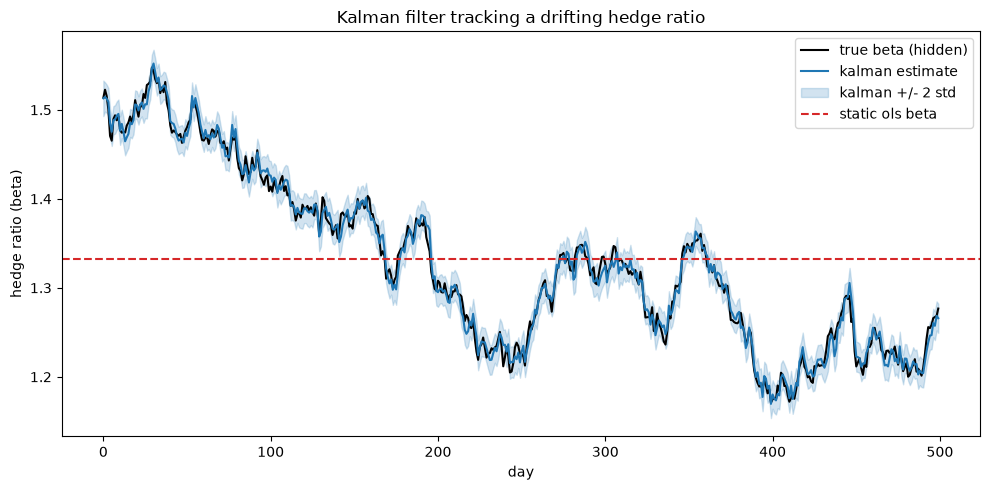

In [6]:
beta_std = np.sqrt(estimated_P)

plt.figure(figsize=(10, 5))
plt.plot(true_beta, label="true beta (hidden)", color="black")
plt.plot(estimated_beta, label="kalman estimate", color="tab:blue")
plt.fill_between(range(num_days),
                 estimated_beta - 2 * beta_std,
                 estimated_beta + 2 * beta_std,
                 color="tab:blue", alpha=0.2, label="kalman +/- 2 std")
plt.axhline(static_ols_beta, color="tab:red", linestyle="--", label="static ols beta")
plt.xlabel("day")
plt.ylabel("hedge ratio (beta)")
plt.title("Kalman filter tracking a drifting hedge ratio")
plt.legend()
plt.tight_layout()
plt.show()

## Experiments

The filter above used the true Q and R. However, real data won't give me those so I want to see what happens when they're wrong.

In [7]:
def run_kalman_filter(x_prices, y_prices, process_noise_Q, measurement_noise_R,
                      initial_beta_guess, initial_uncertainty_P):
    num_days = len(x_prices)
    estimated_beta = np.zeros(num_days)
    estimated_P = np.zeros(num_days)

    beta_previous = initial_beta_guess
    P_previous = initial_uncertainty_P

    for day in range(num_days):
        x_today = x_prices[day]
        y_today = y_prices[day]

        beta_predicted = beta_previous
        P_predicted = P_previous + process_noise_Q

        innovation = y_today - x_today * beta_predicted
        innovation_variance = x_today ** 2 * P_predicted + measurement_noise_R
        kalman_gain = P_predicted * x_today / innovation_variance

        beta_updated = beta_predicted + kalman_gain * innovation
        P_updated = (1 - kalman_gain * x_today) * P_predicted

        estimated_beta[day] = beta_updated
        estimated_P[day] = P_updated

        beta_previous = beta_updated
        P_previous = P_updated

    return estimated_beta, estimated_P

In [8]:
# sanity check: the function should reproduce the loop above exactly
check_beta, check_P = run_kalman_filter(x_prices, y_prices, process_noise_Q,
                                        measurement_noise_R, initial_beta_guess,
                                        initial_uncertainty_P)
print("max difference vs loop above:", np.max(np.abs(check_beta - estimated_beta)))

max difference vs loop above: 0.0


### Experiment 1: wrong Q

True Q is $10^{-4}$. I try 100x too small and 100x too large.

**My prediction:** For 100x too small, a smooth line that lags behind $\beta$, for 100x too large, a noisier line but doesn't lag

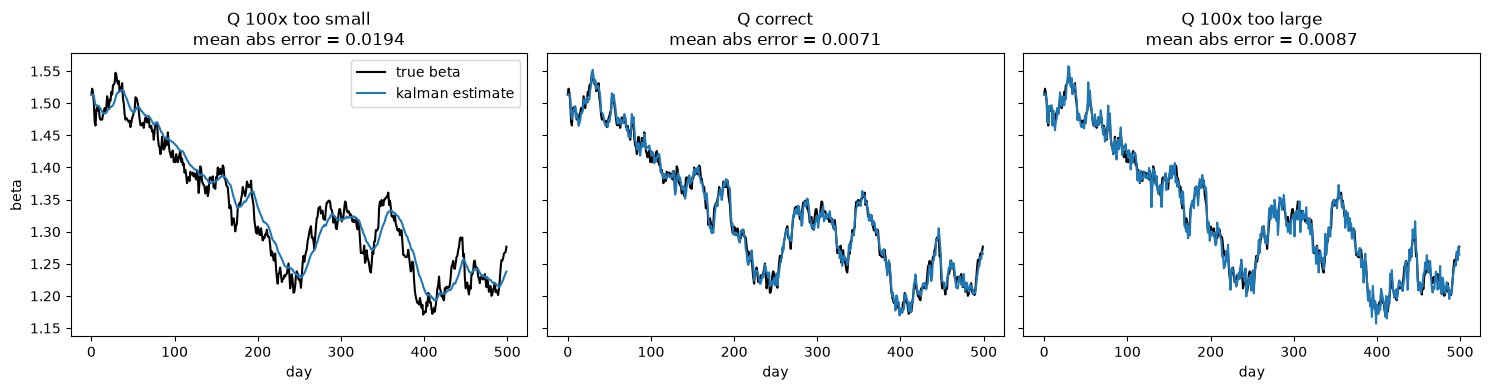

In [9]:
q_values = [1e-6, 1e-4, 1e-2]
q_labels = ["Q 100x too small", "Q correct", "Q 100x too large"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for axis, q_value, q_label in zip(axes, q_values, q_labels):
    beta_for_this_q, _ = run_kalman_filter(x_prices, y_prices, q_value,
                                           measurement_noise_R, initial_beta_guess,
                                           initial_uncertainty_P)
    error = np.mean(np.abs(beta_for_this_q[50:] - true_beta[50:]))

    axis.plot(true_beta, color="black", label="true beta")
    axis.plot(beta_for_this_q, color="tab:blue", label="kalman estimate")
    axis.set_title(f"{q_label}\nmean abs error = {error:.4f}")
    axis.set_xlabel("day")

axes[0].set_ylabel("beta")
axes[0].legend()
plt.tight_layout()
plt.show()

With Q 100× too small the estimate was smooth but lagged behind the true beta, with a mean absolute error of 0.0194. With the correct Q the error was 0.0071. With Q 100× too large the estimate was jittery but didn’t lag, with an error of 0.0087.

### Experiment 2: wrong R

True R is 1. I try much smaller and much larger values, with Q at its correct value.

**My prediction:** For an R too small, it may behave like the too-large Q since the filter may think that the data is almost noise-free. For an R too large, it may behave like the too-small Q which is smooth and lagged.

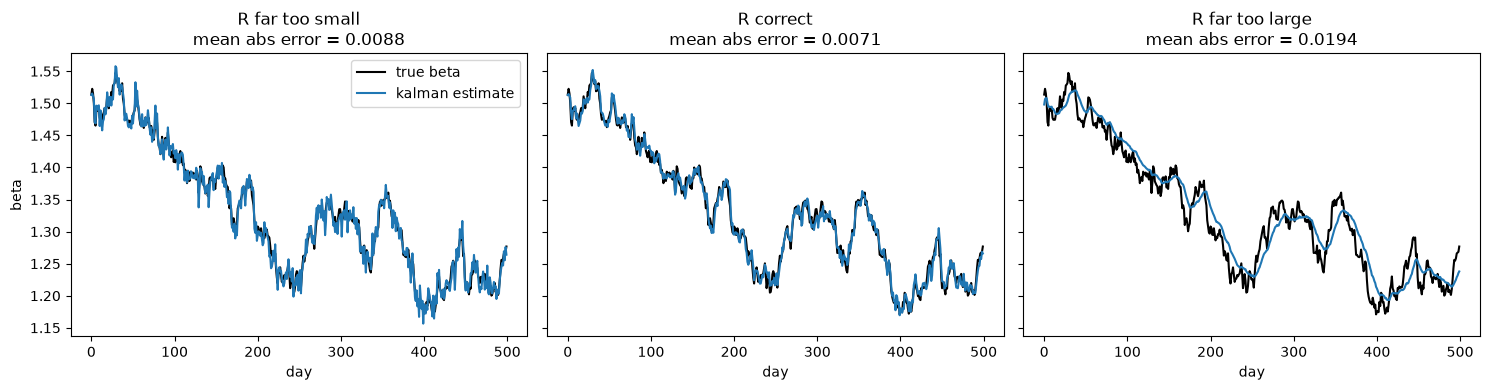

In [10]:
r_values = [1e-4, 1.0, 100.0]
r_labels = ["R far too small", "R correct", "R far too large"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for axis, r_value, r_label in zip(axes, r_values, r_labels):
    beta_for_this_r, _ = run_kalman_filter(x_prices, y_prices, process_noise_Q,
                                           r_value, initial_beta_guess,
                                           initial_uncertainty_P)
    error = np.mean(np.abs(beta_for_this_r[50:] - true_beta[50:]))

    axis.plot(true_beta, color="black", label="true beta")
    axis.plot(beta_for_this_r, color="tab:blue", label="kalman estimate")
    axis.set_title(f"{r_label}\nmean abs error = {error:.4f}")
    axis.set_xlabel("day")

axes[0].set_ylabel("beta")
axes[0].legend()
plt.tight_layout()
plt.show()

R far too small (1e-4) gave a jittery estimate (error 0.0088, daily wiggle 0.0179), very similar to the too-large Q case. R far too large (100) gave a smooth, lagging estimate (error 0.0194, daily wiggle 0.0024), very similar to the too-small Q case. So R and Q work as opposites: what matters is their ratio, not either one alone. Scaling both Q and R by 10 changed the estimate by only about 2e-16, which is just rounding error. That matches the formula, since the gain $K = \frac{P \cdot x}{x^2 P + R}$ doesn’t change when P and R are scaled together.

In [11]:
# scale Q and R by the same factor and see if the estimate changes
beta_original, _ = run_kalman_filter(x_prices, y_prices, process_noise_Q,
                                     measurement_noise_R, initial_beta_guess,
                                     initial_uncertainty_P)
beta_scaled, _ = run_kalman_filter(x_prices, y_prices, process_noise_Q * 10,
                                   measurement_noise_R * 10, initial_beta_guess,
                                   initial_uncertainty_P)
print("max difference after day 50:", np.max(np.abs(beta_original[50:] - beta_scaled[50:])))

max difference after day 50: 2.220446049250313e-16


Multiplying both Q and R by 10 changed the estimate by at most 2.2e-16 after day 50, which is floating-point rounding, so the two runs are effectively identical.

### Experiment 3: bad initial uncertainty

My initial guess for beta is 0 but the truth is about 1.5. How long does the filter take to recover depending on how confident it is in that wrong guess?

**My prediction:** P0 and P1 will look identical and one line sits on another. For a tiny P0, it will start far below.

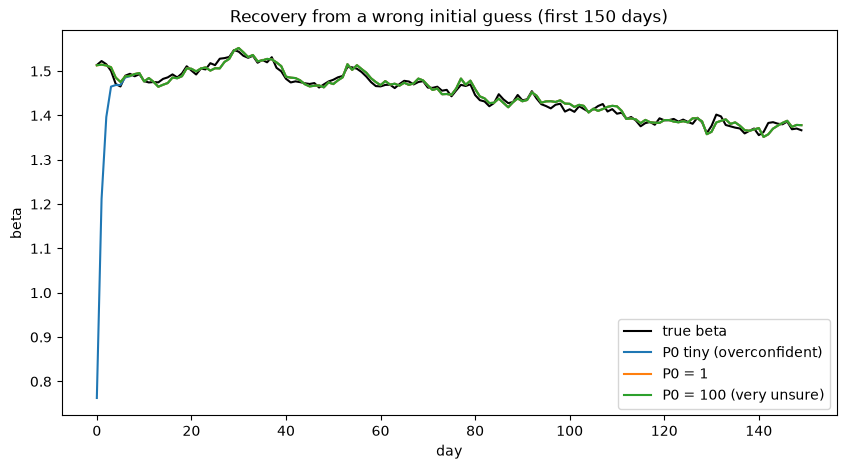

In [12]:
p_values = [1e-6, 1.0, 100.0]
p_labels = ["P0 tiny (overconfident)", "P0 = 1", "P0 = 100 (very unsure)"]

plt.figure(figsize=(10, 5))
plt.plot(true_beta[:150], color="black", label="true beta")

for p_value, p_label in zip(p_values, p_labels):
    beta_for_this_p, _ = run_kalman_filter(x_prices, y_prices, process_noise_Q,
                                           measurement_noise_R, initial_beta_guess,
                                           p_value)
    plt.plot(beta_for_this_p[:150], label=p_label)

plt.xlabel("day")
plt.ylabel("beta")
plt.title("Recovery from a wrong initial guess (first 150 days)")
plt.legend()
plt.show()

With P0 = 1 or P0 = 100 the filter jumped to about the right beta on day 0 (estimate 1.513 against a true value near 1.51), so the two curves are identical and one hides the other. With a tiny P0 (1e-6) the filter trusted its wrong guess: the day-0 estimate was only 0.763, then 1.212, 1.396, and 1.465 by day 3.

### Experiment 4: a sudden jump in the true beta

Real relationships can break suddenly. I make the true beta jump by 0.3 at day 250 and compare how different Q values adapt. A random-walk model with small steps isn't built for a jump, so this is a stress test of Q.

**My prediction:** Q correct and Q too large: both adapt within a few days since a big surprise gets a big enough gain to react, while Q too small: climbs slowly toward the new level and needs roughly 50 days to catch up.

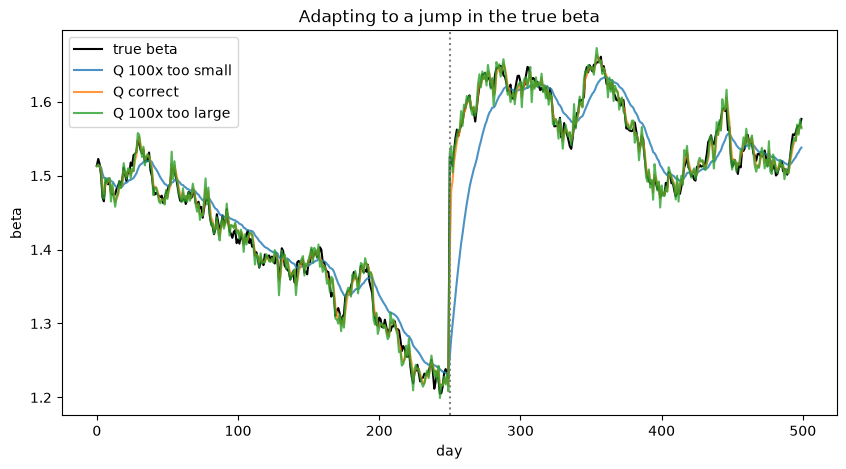

In [13]:
jump_day = 250
jump_size = 0.3

true_beta_with_jump = true_beta.copy()
true_beta_with_jump[jump_day:] = true_beta_with_jump[jump_day:] + jump_size

# same x and same noise as before, only the true beta changed
y_prices_with_jump = true_beta_with_jump * x_prices + measurement_noise

plt.figure(figsize=(10, 5))
plt.plot(true_beta_with_jump, color="black", label="true beta")

for q_value, q_label in zip(q_values, q_labels):
    beta_for_this_q, _ = run_kalman_filter(x_prices, y_prices_with_jump, q_value,
                                           measurement_noise_R, initial_beta_guess,
                                           initial_uncertainty_P)
    plt.plot(beta_for_this_q, label=q_label, alpha=0.8)

plt.axvline(jump_day, color="gray", linestyle=":")
plt.xlabel("day")
plt.ylabel("beta")
plt.title("Adapting to a jump in the true beta")
plt.legend()
plt.show()

After the 0.3 jump at day 250, the correct Q was within 0.05 of the true beta after 1 day and the too-large Q reacted immediately. The too-small Q took 28 days to get within 0.05, and the plot shows it still catching up for longer after that. This is the trade-off: a large Q adapts fast to a break but is jittery in calm periods (experiment 1), while a small Q is smooth in calm periods but slow when the relationship really changes. For a pairs trade, a slow filter would keep using an old hedge ratio for a month after the relationship moved.

## Notes

- The filter beats static OLS here partly because I gave it the true Q and R. On real data I won't know them, so tuning Q is the hard part.
- Static OLS sits near the middle of the true path: right on average, wrong on almost every day.

**Next:** extend the state to include an intercept, so the filter works on real price pairs.